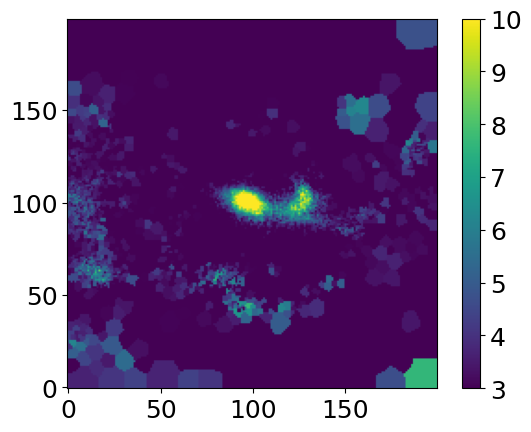

640.7346227044236


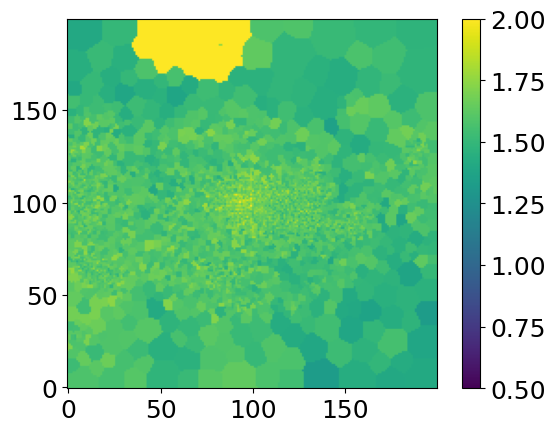

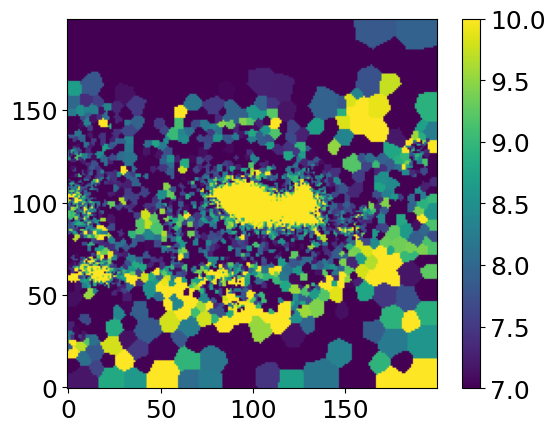

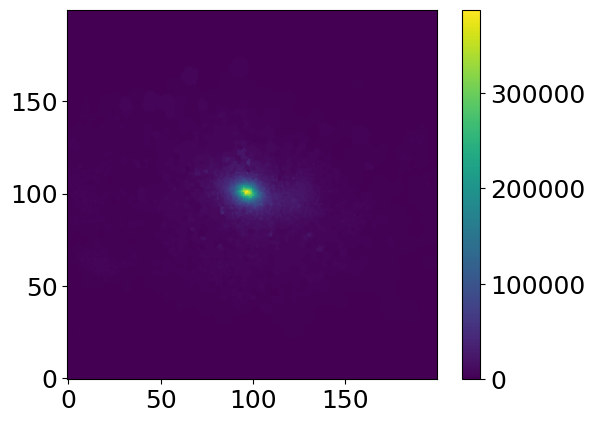

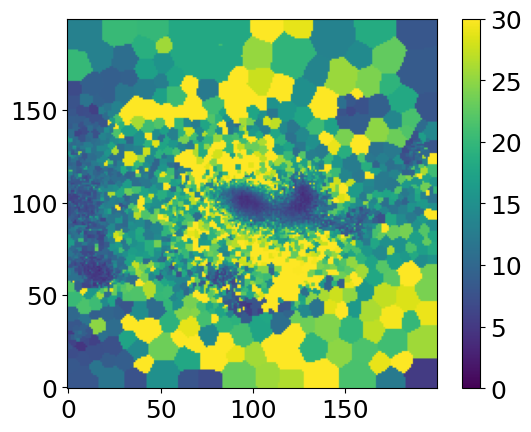

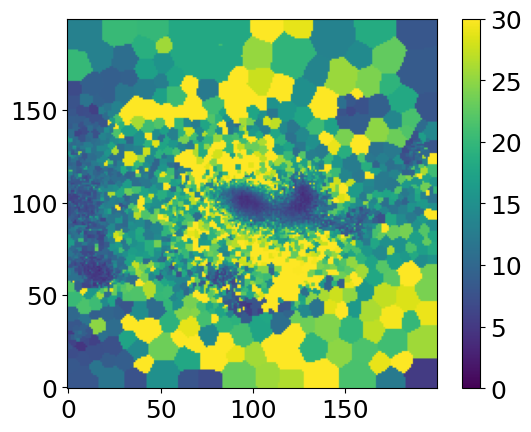

In [22]:

from pathlib import Path
from urllib import request

from time import perf_counter as clock

import math

from astropy.io import fits
import astropy.io.fits as pyfits
from astropy.wcs import WCS
from astropy.stats import sigma_clip

import numpy as np
import matplotlib.pyplot as plt

from ppxf.ppxf import ppxf, robust_sigma
import ppxf.ppxf_util as util
import ppxf.sps_util as lib

from os import path

import os

import fnmatch

from tqdm import tqdm

import pandas as pd

from joblib import Parallel, delayed, parallel_backend
import traceback

from glob import glob

from mpdaf.obj import Cube, WaveCoord


plt.rcParams.update({'font.size': 18})

folder ='NGC_584'

save_folder = '/Users/volivares/Desktop/MUSE_BCGs_analysis/PPXF_mycode/'+folder+'/'

from astropy.io import fits

hdul = fits.open(save_folder+"Gas1G_emission_lines_voronoi.fits")
#hdul = fits.open(save_folder+"Gas_emission_lines_1G.fits")
head = hdul[0].header
#hdul.info()


chi2,chi22 =hdul['CHI2'].data, hdul['CHI2'].data
map_vel_gas,map_vel_gas_err =hdul['[NII]6583_D_VEL'].data, hdul['[NII]6583_D_VEL_ERR'].data
map_sigma_gas,map_sigma_gas_err = hdul['[NII]6583_D_SIGMA'].data, hdul['[NII]6583_D_VEL_ERR'].data
ha_clip, ha_err_clip = hdul['[NII]6583_D_SB'].data, hdul['[NII]6583_D_SB_ERR'].data
ha_flux, ha_flux_err= hdul['[NII]6583_D_FLUX'].data, hdul['[NII]6583_D_FLUX_ERR'].data

A_rN= hdul['[NII]6583_D_A/rN'].data

plt.imshow(A_rN, vmin=3, vmax=10, origin='lower')
plt.colorbar()
plt.show()


flux_threshold = 3 * np.nanmedian(ha_err_clip)

print(flux_threshold)


plt.imshow(chi2, vmin=0.5, vmax=2, origin='lower')
plt.colorbar()
plt.show()


SN = ha_clip / ha_err_clip
plt.imshow(SN, vmin=7, vmax=10, origin='lower')
plt.colorbar()
plt.show()


plt.imshow(ha_clip, origin='lower')
plt.colorbar()
plt.show()


plt.imshow(map_vel_gas_err, vmin=0, vmax=30, origin='lower')
plt.colorbar()
plt.show()

plt.imshow(map_sigma_gas_err, vmin=0, vmax=30, origin='lower')
plt.colorbar()
plt.show()

In [17]:

def clip_map_velocity_gas(value_map, error_map, ha_clip, ha_err_clip, min_vel_err = 12):
    # Evitar divisiones por cero
    with np.errstate(divide='ignore', invalid='ignore'):
        rel_error = np.abs(error_map / value_map)
        snr = np.abs(ha_clip / ha_err_clip)
        # deviation = np.abs(value_map - np.nanmedian(value_map))

    # Construir máscaras individuales
    # mask_rel = rel_error > max_rel_error
    # mask_dev = deviation_over_error > max_deviation_sigma
    mask_snr = snr < 0.5

    
    mask_vel = error_map > min_vel_err 
    # mask_sigma = error_sigma > 3
    
    # Combinar todas las condiciones + NaNs
    total_mask = mask_vel | mask_snr

    # Aplicar máscara al mapa
    clipped_map = np.where(total_mask, np.nan, value_map)

    return clipped_map



def clip_map_sigma_gas(value_map, error_map, ha_clip, ha_err_clip, min_vel_err):

    # Evitar divisiones por cero
    with np.errstate(divide='ignore', invalid='ignore'):
        rel_error = np.abs(error_map / value_map)
        snr = np.abs(ha_clip / ha_err_clip)
        # deviation = np.abs(value_map - np.nanmedian(value_map))
        # deviation_over_error = deviation / error_map

    # Construir máscaras individuales
    # mask_rel = rel_error > max_rel_error
    # mask_dev = deviation_over_error > max_deviation_sigma
    mask_snr = snr < 0.5

    
    mask_vel = error_map > min_vel_err 
    # mask_sigma = error_sigma > 3
    
    # Combinar todas las condiciones + NaNs
    total_mask = mask_vel | mask_snr

    # Aplicar máscara al mapa
    clipped_map = np.where(total_mask, np.nan, value_map)

    return clipped_map


def clip_map_flux(value_map, error_map, error_vel_gas,min_vel_err, error_sigma_gas,min_sigma_err,chi2):

    # Evitar divisiones por cero
    with np.errstate(divide='ignore', invalid='ignore'):
        rel_error = np.abs(error_map / value_map)
        snr = np.abs(value_map / error_map)
        # deviation = np.abs(value_map - np.nanmedian(value_map))
        # deviation_over_error = deviation / error_map

    # Construir máscaras individuales
    # Construir máscaras individuales
    mask_snr = snr < 7
    mask_chi2 =  (chi2 > 2)

    mask_vel = error_vel_gas > min_vel_err 
    mask_sigma = error_sigma_gas > min_sigma_err 
    
    # Combinar todas las condiciones + NaNs
    total_mask = mask_vel  | mask_snr  | mask_sigma 


    # Aplicar máscara al mapa
    clipped_map = np.where(total_mask, np.nan, value_map)
    return clipped_map

def plot_simple(array):
    plt.figure(figsize = (7,7))
    plt.imshow(array, origin = 'lower', cmap = cm)
    plt.colorbar()

    plt.tight_layout()
    plt.show()


def save_fits_clip(fitsfile_name,data,header):
    from astropy.io import fits
    fits.writeto(f'{save_folder}/'+fitsfile_name+'.fits',data=data,header=header,overwrite=True)




## Make velocity maps 


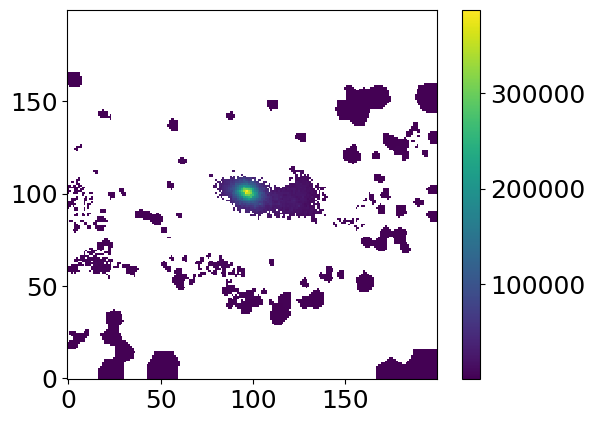

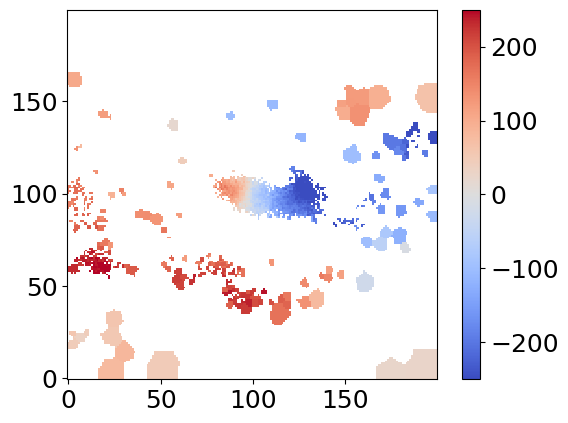

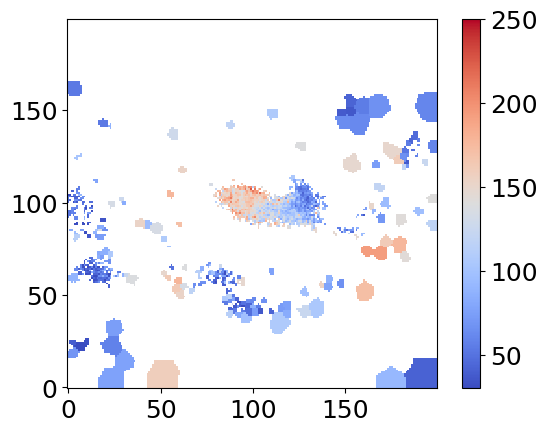

In [23]:

min_vel_err=20
min_sigma_err=20
map_gas_clipped = clip_map_flux(ha_clip, ha_err_clip*np.sqrt(chi2), map_vel_gas_err,min_vel_err*np.sqrt(chi2), map_sigma_gas_err*np.sqrt(chi2), min_sigma_err,chi2)
#map_gas_clipped[map_gas_clipped<flux_threshold] = np.nan

mask = map_gas_clipped/map_gas_clipped
fits.writeto(f'{save_folder}/{folder}_gas_flux_clipping.fits',data=map_gas_clipped,header=head,overwrite=True)

plt.imshow(map_gas_clipped,origin='lower',interpolation='nearest')
plt.colorbar()
plt.show()

map_vel_gas_clipped = clip_map_velocity_gas(map_vel_gas,map_vel_gas_err, ha_clip, ha_err_clip, min_vel_err = 20)
fits.writeto(f'{save_folder}/{folder}_gas_velocity_clipping.fits',data=map_vel_gas_clipped*mask,header=head,overwrite=True)

plt.imshow(map_vel_gas*mask,vmin=-250,vmax=250,cmap='coolwarm',origin='lower',interpolation='nearest')
plt.colorbar()
plt.show()

map_sigma_gas_clipped = clip_map_sigma_gas(map_sigma_gas,map_sigma_gas_err,ha_clip, ha_err_clip,min_vel_err = 20)
fits.writeto(f'{save_folder}/{folder}_gas_sigma_clipping.fits',data=map_sigma_gas_clipped * mask,header=head,overwrite=True)

plt.imshow(map_sigma_gas*mask,vmin=30,vmax=250,cmap='coolwarm',origin='lower',interpolation='nearest')
plt.colorbar()
plt.show()





## Make flux maps 

In [13]:
gas_names_single = np.array(['HB4861_FLUX', 'OIII4958_FLUX', 'OIII5006_FLUX', 'NI5197_FLUX',
       'NI5200_FLUX', 'NII5754_FLUX', 'HEI5875_FLUX',
       'OI6300_FLUX', 'OI6363_FLUX', 'NII6548_FLUX', 'HA6562_FLUX',
       'NII6583_FLUX', 'SII6716_FLUX', 'SII6730_FLUX'])
gas_names_save = np.array(['H_BETA_FLUX', 'OIII_4958_FLUX', 'OIII_5007_FLUX', 'NI_5197_FLUX',
       'NI_5200_FLUX', 'NII_5754_FLUX', 'HEI_5875_FLUX',
       'OI_6300_FLUX', 'OI_6363_FLUX', 'NII_6548_FLUX', 'H_ALPHA_FLUX',
       'NII_6584_FLUX', 'SII_6717_FLUX', 'SII_6731_FLUX'])

for filename, filesave in zip(gas_names_single,gas_names_save): # in range(0,18):
    map_fluxx, map_errs = eline_hdu[filename].data, eline_hdu[filename+'_ERR'].data
    map_clipp = clip_map_flux(map_fluxx,map_errs,map_vel_gas_err,min_vel_err=500)
				
    save_fits_clip(filesave,map_clipp,head)
				


In [22]:
ratio = eline_hdu['HA6562_FLUX'].data/eline_hdu['HB4861_FLUX'].data
save_fits_clip('ratio_Halpha_Hbeta',ratio,head)

/var/folders/w9/1mfj5xcn4qd25rq93f5gj9_40000gn/T/ipykernel_38475/1047150287.py:1: RuntimeWarning: divide by zero encountered in divide
  ratio = eline_hdu['HA6562_FLUX'].data/eline_hdu['HB4861_FLUX'].data
/var/folders/w9/1mfj5xcn4qd25rq93f5gj9_40000gn/T/ipykernel_38475/1047150287.py:1: RuntimeWarning: invalid value encountered in divide
  ratio = eline_hdu['HA6562_FLUX'].data/eline_hdu['HB4861_FLUX'].data
